# 04. Классификатор на базе трансформера: ruBERT + LoRA

* Базовая модель: **`ai-forever/ruBert-base`** (`AutoModelForSequenceClassification`, 64 класса).
* Тонкая настройка параметро-эффективным методом **LoRA** (`peft`): `r=16, alpha=32`,
  `target_modules=["query", "value", "dense"]`, `dropout=0.1`.
* Обучение в **BF16** на RTX 5070, до 4 эпох с **Early Stopping** по macro-F1 на validation.
* Оценка на официальной **test**-выборке: Accuracy, macro-F1, матрица ошибок по всем авторам.

In [1]:
import json
import os
import shutil
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from peft import LoraConfig, PeftModel, TaskType, get_peft_model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED, MODELS, FIG, REPORTS = ROOT / "data/processed", ROOT / "models", ROOT / "reports/figures", ROOT / "reports"
RUNS = ROOT / "data" / "lora_runs"
SEED = 42
set_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
sns.set_theme(style="whitegrid")

BASE_MODEL = "ai-forever/ruBert-base"
MAX_LENGTH = 256
print(torch.__version__, torch.cuda.get_device_name(0), "bf16:", torch.cuda.is_bf16_supported())

W1031 12:49:49.322000 27424 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


2.11.0+cu128 NVIDIA GeForce RTX 5070 bf16: True


In [2]:
import joblib  # noqa: E402

label_encoder = joblib.load(MODELS / "label_encoder.pkl")
classes = label_encoder.classes_.tolist()
num_classes = len(classes)
id2label = dict(enumerate(classes))
label2id = {c: i for i, c in id2label.items()}

train_df = pd.read_parquet(PROCESSED / "chunks_train.parquet")
val_df = pd.read_parquet(PROCESSED / "chunks_validation.parquet")
test_df = pd.read_parquet(PROCESSED / "chunks_test.parquet")
if os.environ.get("SMOKE_TEST"):  # быстрый прогон для проверки кода
    train_df, val_df, test_df = (d.sample(n, random_state=SEED) for d, n in ((train_df, 3000), (val_df, 500), (test_df, 500)))
print(len(train_df), len(val_df), len(test_df), "| classes:", num_classes)

110285 9735 9748 | classes: 64


### Токенизация

In [3]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)


class ChunkDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame):
        self.enc = tokenizer(df["text"].tolist(), truncation=True, max_length=MAX_LENGTH)
        self.labels = label_encoder.transform(df["author"])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item


t0 = time.perf_counter()
train_ds, val_ds, test_ds = ChunkDataset(train_df), ChunkDataset(val_df), ChunkDataset(test_df)
lens = np.array([len(x) for x in train_ds.enc["input_ids"]])
print(f"Токенизация: {time.perf_counter() - t0:.0f} c")
print(f"Длина в токенах: median={np.median(lens):.0f}, p95={np.percentile(lens, 95):.0f}, доля обрезанных={np.mean(lens >= MAX_LENGTH):.1%}")

Токенизация: 14 c
Длина в токенах: median=242, p95=256, доля обрезанных=29.7%


### Модель и LoRA-адаптер

In [4]:
base_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL, num_labels=num_classes, id2label=id2label, label2id=label2id
)
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=16,
    lora_alpha=32,
    target_modules=["query", "value", "dense"],
    lora_dropout=0.1,
    bias="none",
)
model = get_peft_model(base_model, peft_config)
model.print_trainable_parameters()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai-forever/ruBert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

trainable params: 2,433,088 || all params: 180,789,632 || trainable%: 1.3458


### Обучение (BF16, Early Stopping)

In [5]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}


BATCH = 64
EPOCHS = 1 if os.environ.get("SMOKE_TEST") else 4
steps_per_epoch = int(np.ceil(len(train_ds) / BATCH))
shutil.rmtree(RUNS, ignore_errors=True)
args = TrainingArguments(
    output_dir=str(RUNS),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=128,
    learning_rate=3e-4,
    weight_decay=0.01,
    warmup_steps=int(0.06 * steps_per_epoch * EPOCHS),
    lr_scheduler_type="linear",
    bf16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=100,
    report_to="none",
    dataloader_num_workers=0,
    seed=SEED,
)
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)
t0 = time.perf_counter()
train_result = trainer.train()
train_time = time.perf_counter() - t0
print(f"Время обучения: {train_time / 60:.1f} мин, пик VRAM: {torch.cuda.max_memory_allocated() / 2**30:.1f} GB")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.542970,0.526911,0.854751,0.671525
2,0.290863,0.331192,0.908475,0.734157
3,0.148382,0.307108,0.919363,0.749075
4,0.077314,0.283156,0.926348,0.749779


Время обучения: 52.0 мин, пик VRAM: 8.6 GB


 epoch  eval_loss  eval_accuracy  eval_f1_macro
   1.0   0.526911       0.854751       0.671525
   2.0   0.331192       0.908475       0.734157
   3.0   0.307108       0.919363       0.749075
   4.0   0.283156       0.926348       0.749779


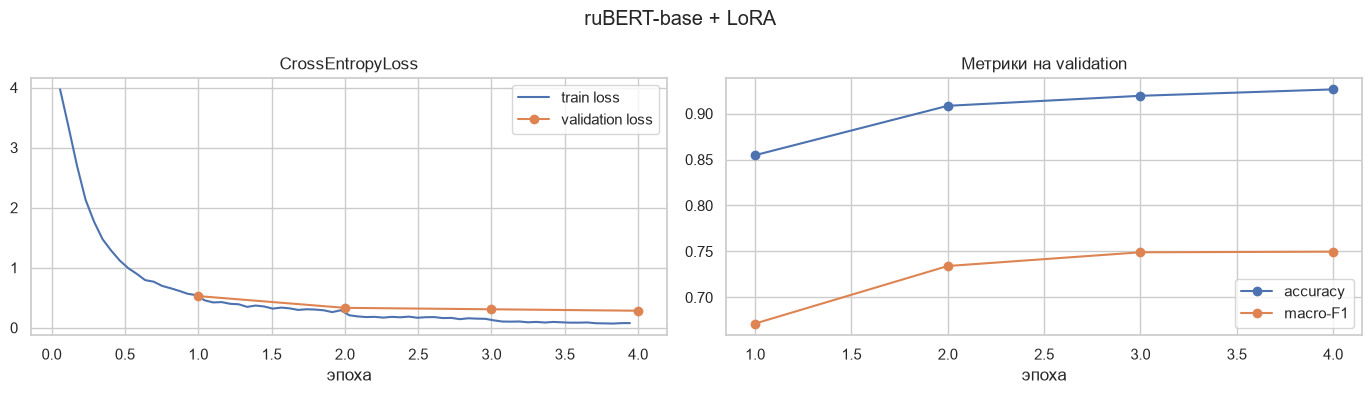

In [6]:
log = pd.DataFrame(trainer.state.log_history)
log.to_csv(REPORTS / "lora_history.csv", index=False)
tr_log = log.dropna(subset=["loss"]) if "loss" in log.columns else pd.DataFrame({"epoch": [], "loss": []})
ev_log = log.dropna(subset=["eval_loss"])
print(ev_log[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(tr_log.epoch, tr_log.loss, label="train loss")
axes[0].plot(ev_log.epoch, ev_log.eval_loss, "o-", label="validation loss")
axes[0].set_xlabel("эпоха")
axes[0].set_title("CrossEntropyLoss")
axes[0].legend()
axes[1].plot(ev_log.epoch, ev_log.eval_accuracy, "o-", label="accuracy")
axes[1].plot(ev_log.epoch, ev_log.eval_f1_macro, "o-", label="macro-F1")
axes[1].set_xlabel("эпоха")
axes[1].set_title("Метрики на validation")
axes[1].legend()
plt.suptitle("ruBERT-base + LoRA")
plt.tight_layout()
plt.savefig(FIG / "lora_training.png", dpi=120)
plt.show()

### Оценка на официальной test-выборке

In [7]:
pred_out = trainer.predict(test_ds)
probs = torch.softmax(torch.from_numpy(pred_out.predictions).float(), dim=1).numpy()
y_true = test_ds.labels
y_pred = probs.argmax(1)
chunk_metrics = {"accuracy": accuracy_score(y_true, y_pred), "f1_macro": f1_score(y_true, y_pred, average="macro")}
print("test (фрагменты ~1000 симв.):", chunk_metrics)

doc_probs = pd.DataFrame(probs).groupby(test_df["doc_id"].values).mean()
doc_true = test_df.groupby("doc_id")["author"].first().loc[doc_probs.index]
doc_pred = np.array(classes)[doc_probs.values.argmax(1)]
doc_metrics = {"accuracy": accuracy_score(doc_true, doc_pred), "f1_macro": f1_score(doc_true, doc_pred, average="macro")}
print("test (документы, ~14 000 симв.):", doc_metrics)
np.save(REPORTS / "lora_test_probs.npy", probs)

test (фрагменты ~1000 симв.): {'accuracy': 0.9172137874435782, 'f1_macro': 0.8507164379398455}
test (документы, ~14 000 симв.): {'accuracy': 0.9915254237288136, 'f1_macro': 0.9853366530655797}


In [8]:
present = np.unique(np.concatenate([y_true, y_pred]))
report = classification_report(y_true, y_pred, labels=present, target_names=[classes[i] for i in present], zero_division=0, output_dict=True)
per_class = pd.DataFrame(report).T.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
per_class = per_class.sort_values("support", ascending=False)
per_class.to_csv(REPORTS / "lora_per_class_report.csv")
per_class.round(3)

,precision,recall,f1-score,support
Лесков Н,0.990,0.892,0.939,864.0
Достоевский Ф,0.969,0.911,0.939,833.0
Толстой Л,0.958,0.928,0.943,708.0
Чехов А,0.820,0.981,0.893,517.0
Карамзин Н,0.965,0.996,0.980,467.0
Салтыков-Щедрин М,0.909,0.960,0.934,427.0
Пушкин А,0.947,0.933,0.940,401.0
Мамин-Сибиряк Д,0.975,0.980,0.977,392.0
Гончаров И,0.948,0.873,0.909,314.0
Тургенев И,0.755,0.957,0.844,299.0


### Матрица ошибок (все авторы test-выборки, нормировка по строкам)

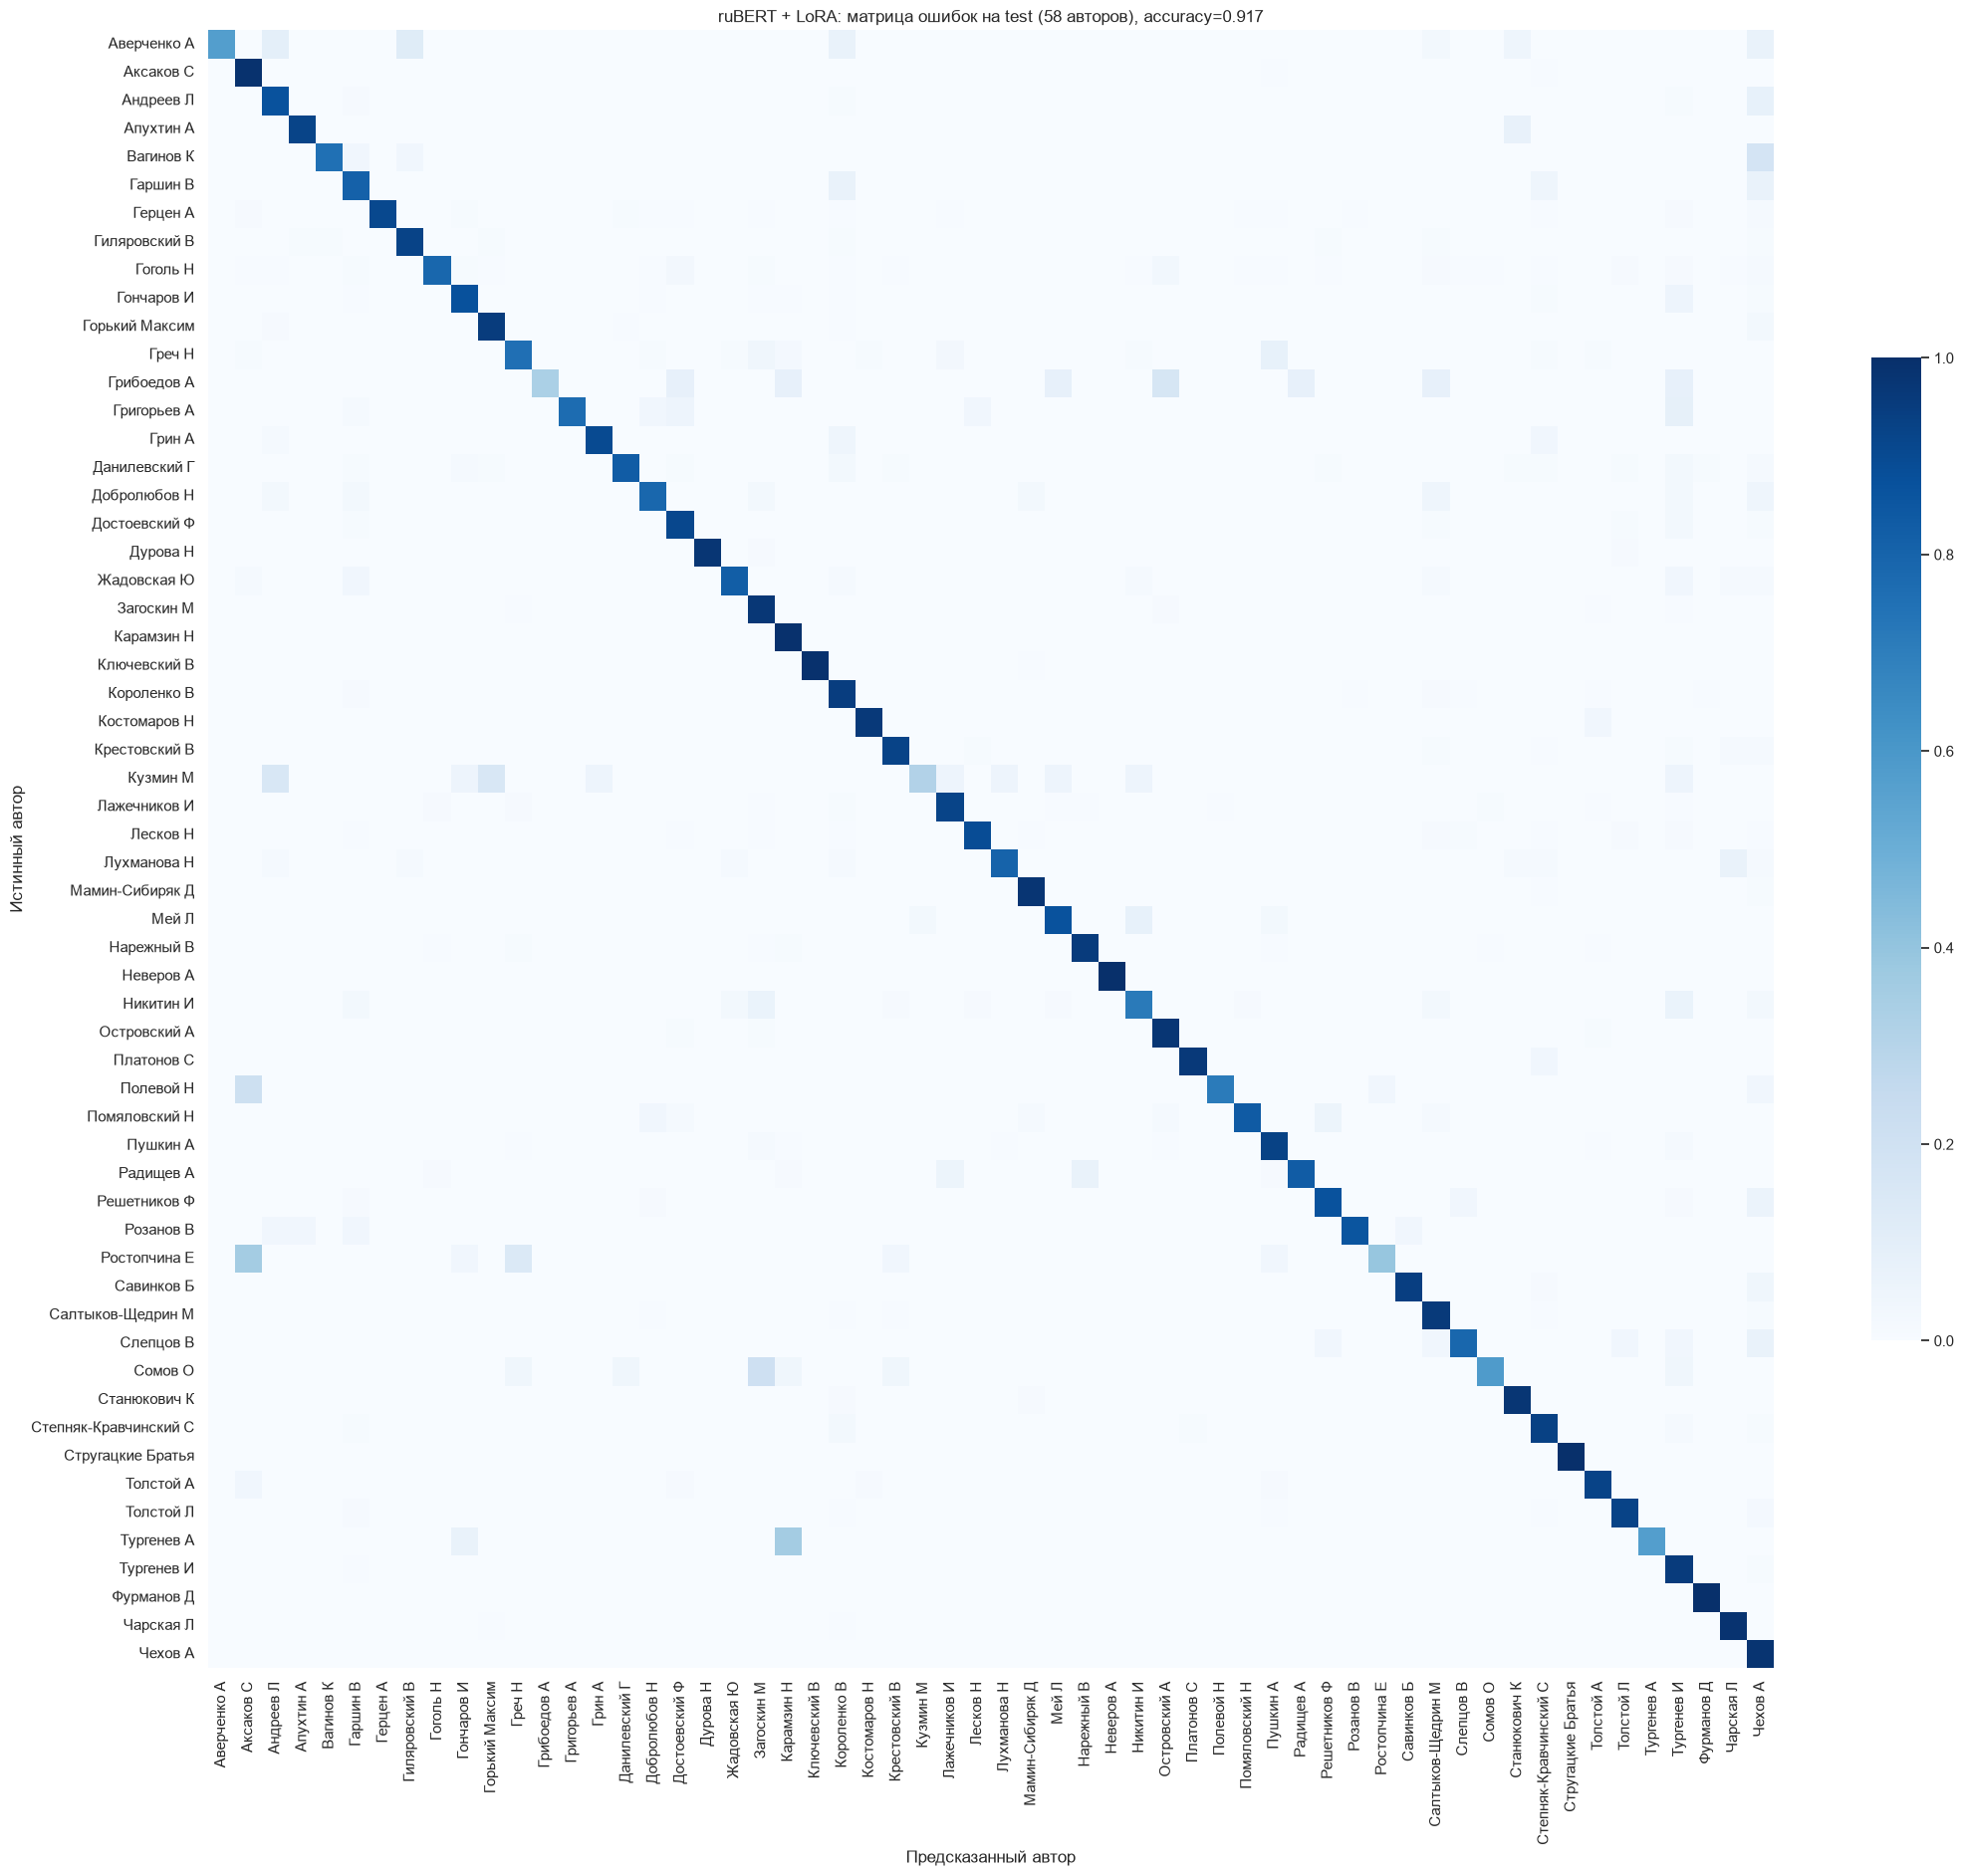

In [9]:
test_labels = np.unique(y_true)
cm = confusion_matrix(y_true, y_pred, labels=test_labels, normalize="true")
fig, ax = plt.subplots(figsize=(22, 19))
sns.heatmap(cm, cmap="Blues", ax=ax, xticklabels=[classes[i] for i in test_labels], yticklabels=[classes[i] for i in test_labels], vmin=0, vmax=1, cbar_kws={"shrink": 0.6})
ax.set_xlabel("Предсказанный автор")
ax.set_ylabel("Истинный автор")
ax.set_title(f"ruBERT + LoRA: матрица ошибок на test ({len(test_labels)} авторов), accuracy={chunk_metrics['accuracy']:.3f}")
plt.tight_layout()
plt.savefig(FIG / "lora_confusion_matrix.png", dpi=110)
plt.show()

In [10]:
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(classes[test_labels[i]], classes[test_labels[j]], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:10], off.shape))]
pd.DataFrame(pairs, columns=["истинный", "предсказан как", "доля"]).round(3)

,истинный,предсказан как,доля
0,Ростопчина Е,Аксаков С,0.357
1,Тургенев А,Карамзин Н,0.357
2,Полевой Н,Аксаков С,0.214
3,Сомов О,Загоскин М,0.208
4,Вагинов К,Чехов А,0.179
5,Грибоедов А,Островский А,0.167
6,Кузмин М,Горький Максим,0.158
7,Кузмин М,Андреев Л,0.158
8,Ростопчина Е,Греч Н,0.143
9,Аверченко А,Гиляровский В,0.119


### Сохранение адаптера LoRA

In [11]:
ADAPTER_DIR = MODELS / "lora_classifier"
trainable, total = model.get_nb_trainable_parameters()
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
(ADAPTER_DIR / "labels.json").write_text(
    json.dumps({"classes": classes, "max_length": MAX_LENGTH, "base_model": BASE_MODEL}, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

adapter_mb = sum(f.stat().st_size for f in ADAPTER_DIR.glob("adapter_model.*")) / 2**20
base_mb = (total - trainable) * 4 / 2**20
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<28} {f.stat().st_size / 2**20:8.2f} MB")
print(f"Веса базовой модели (FP32): {base_mb:.1f} MB | Веса адаптера LoRA: {adapter_mb:.2f} MB")

adapter_config.json              0.00 MB
adapter_model.safetensors        9.30 MB
labels.json                      0.00 MB
README.md                        0.00 MB
tokenizer.json                   3.54 MB
tokenizer_config.json            0.00 MB
Веса базовой модели (FP32): 680.4 MB | Веса адаптера LoRA: 9.30 MB


### Проверка восстановления и латентность инференса

In [12]:
def load_for_inference(device: str):
    base = AutoModelForSequenceClassification.from_pretrained(BASE_MODEL, num_labels=num_classes, id2label=id2label, label2id=label2id)
    m = PeftModel.from_pretrained(base, ADAPTER_DIR).merge_and_unload()
    return m.to(device).eval()


del trainer, model, base_model
torch.cuda.empty_cache()

restored = load_for_inference("cuda")
sample_texts = test_df["text"].iloc[:256].tolist()
with torch.no_grad():
    enc = tokenizer(sample_texts, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors="pt").to("cuda")
    restored_pred = restored(**enc).logits.argmax(1).cpu().numpy()
print("Совпадение предсказаний восстановленной модели:", (restored_pred == y_pred[:256]).mean())


def measure_latency(m, device, n=50):
    texts = test_df["text"].sample(n, random_state=SEED).tolist()
    with torch.inference_mode():
        for t in texts[:3]:  # прогрев
            inp = tokenizer(t, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
            if device == "cuda":
                with torch.autocast("cuda", dtype=torch.bfloat16):
                    m(**inp)
            else:
                m(**inp)
        if device == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for t in texts:
            inp = tokenizer(t, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
            if device == "cuda":
                with torch.autocast("cuda", dtype=torch.bfloat16):
                    logits = m(**inp).logits
            else:
                logits = m(**inp).logits
            torch.softmax(logits.float(), dim=1).cpu()
        if device == "cuda":
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000


lat_gpu = measure_latency(restored, "cuda")
restored_cpu = restored.to("cpu")
lat_cpu = measure_latency(restored_cpu, "cpu", n=20)
print(f"Латентность: GPU {lat_gpu:.1f} мс, CPU {lat_cpu:.1f} мс на запрос (~1000 симв.)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai-forever/ruBert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

Совпадение предсказаний восстановленной модели: 1.0


Латентность: GPU 8.1 мс, CPU 84.5 мс на запрос (~1000 симв.)


In [13]:
metrics = {
    "model": "ruBERT-base + LoRA",
    "official_test_chunks": chunk_metrics,
    "official_test_docs": doc_metrics,
    "best_val_f1_macro": float(ev_log.eval_f1_macro.max()),
    "epochs_trained": float(ev_log.epoch.max()),
    "train_time_min": train_time / 60,
    "latency_gpu_ms": lat_gpu,
    "latency_cpu_ms": lat_cpu,
    "adapter_mb": adapter_mb,
    "base_model_mb": base_mb,
    "trainable_params": int(trainable),
    "total_params": int(total),
}
(REPORTS / "metrics_lora.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
shutil.rmtree(RUNS, ignore_errors=True)
metrics

{'model': 'ruBERT-base + LoRA',
 'official_test_chunks': {'accuracy': 0.9172137874435782,
  'f1_macro': 0.8507164379398455},
 'official_test_docs': {'accuracy': 0.9915254237288136,
  'f1_macro': 0.9853366530655797},
 'best_val_f1_macro': 0.7497788250678131,
 'epochs_trained': 4.0,
 'train_time_min': 52.04281671666734,
 'latency_gpu_ms': 8.13434200012125,
 'latency_cpu_ms': 84.48338499874808,
 'adapter_mb': 9.297904968261719,
 'base_model_mb': 680.376220703125,
 'trainable_params': 2433088,
 'total_params': 180789632}